# Parte Comum — Padronização, K-Means e Métricas

Dataset: **Obesity** (`data/parte_comum/ObesityDataSet_raw_and_data_sinthetic.csv`)

## 0. Carregar o Dataset e Preparar Pastas de Saída

In [1]:
# [IA] Google Gemini – carregamento dos dados e importação das bibliotecas
# [IA] GitHub Copilot – estruturação standalone do notebook kmeans_metricas.ipynb e pasta de saída
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

caminho = Path("../../data/parte_comum/ObesityDataSet_raw_and_data_sinthetic.csv")
out_dir = Path("../../out/parte_comum/kmeans")
out_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(caminho).drop_duplicates().reset_index(drop=True)
colunas_num = df.select_dtypes(include=[np.number]).columns.tolist()

print(f"Dataset carregado: {df.shape[0]} linhas x {df.shape[1]} colunas")
print("Variáveis numéricas utilizadas no K-Means:", colunas_num)

Dataset carregado: 2087 linhas x 17 colunas
Variáveis numéricas utilizadas no K-Means: ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']


## 1. Padronização

### Separar o alvo e padronizar as variáveis numéricas

Como o K-Means não pode ter acesso aos rótulos reais durante o agrupamento, guardamos a coluna `NObeyesdad` separada (para usar apenas na etapa de avaliação e métricas) e aplicamos o `StandardScaler` do `scikit-learn` nas variáveis numéricas (`colunas_num`).

In [2]:
# [IA] Google Gemini – separação do alvo e padronização com StandardScaler
X_num = df[colunas_num].copy()
y_real = df["NObeyesdad"].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_num)

df_scaled = pd.DataFrame(X_scaled, columns=colunas_num)

print("--- Conferência após padronização (média próxima de 0 e std próximo de 1) ---")
display(df_scaled.describe().T[["mean", "std", "min", "max"]].round(2))

--- Conferência após padronização (média próxima de 0 e std próximo de 1) ---


,mean,std,min,max
Age,-0.0,1.0,-1.63,5.76
Height,0.0,1.0,-2.71,2.98
Weight,-0.0,1.0,-1.83,3.29
FCVC,-0.0,1.0,-2.66,1.08
NCP,0.0,1.0,-2.23,1.70
CH2O,0.0,1.0,-1.65,1.64
FAF,0.0,1.0,-1.19,2.33
TUE,-0.0,1.0,-1.09,2.20


### Por que a padronização é necessária para o K-Means?

O algoritmo K-Means forma os grupos calculando a distância euclidiana entre os registros e os centroides.

No dataset *Obesity*, as variáveis numéricas estão em escalas muito diferentes: por exemplo, `Weight` varia muito mais numericamente (de 40 a 170) do que `NCP`, que varia de 0 a 4. Sem padronizar os dados, as variáveis com escalas numéricas diferentes teriam pesos diferentes. As com maior escala dominariam o cálculo do K-Means, enquanto as com escalas menores teriam peso irrelevante.

Ao aplicar a padronização com o `StandardScaler`, todas as variáveis numéricas passam a ter média igual a 0 e desvio padrão igual a 1, garantindo que todas as variáveis tenham o mesmo peso, evitando que o agrupamento seja influenciado desproporcionalmente.

*(Nota: registrar também no relatório a justificativa autoral para utilizar apenas as variáveis numéricas padronizadas nesta etapa.)*

## 2. Agrupamento com K-Means

### 2.1 Passada 1 — `k` livre (Método do Cotovelo)

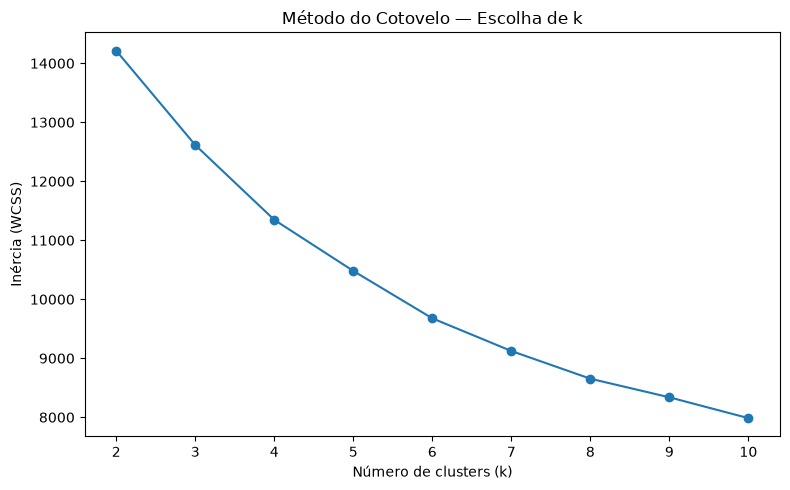

In [3]:
# [IA] Google Gemini – execução do K-Means para k de 2 a 10 e gráfico do Método do Cotovelo
valores_k = range(2, 11)
inercias = []

for k in valores_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inercias.append(km.inertia_)

df_cotovelo = pd.DataFrame({"k": list(valores_k), "inercia": inercias})
df_cotovelo.to_csv(out_dir / "cotovelo.csv", index=False)

plt.figure(figsize=(8, 5))
plt.plot(valores_k, inercias, marker="o")
plt.title("Método do Cotovelo — Escolha de k")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inércia (WCSS)")
plt.xticks(valores_k)
plt.tight_layout()
plt.savefig(out_dir / "cotovelo.png", dpi=150)
plt.show()

**Justificativa autoral da escolha de `k_livre`:**  
O k livre escolhido foi o 4 para preservar equilíbrio entre número de classes (tentar não deixar muitas classes) e inércia.

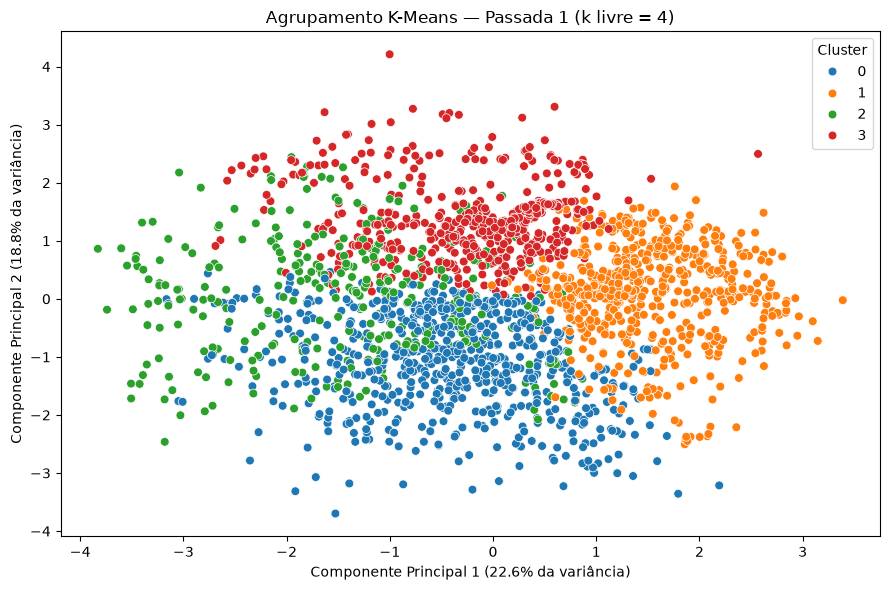

In [4]:
# [IA] Google Gemini – K-Means (Passada 1 com k livre) e projeção 2D via PCA
# [IA] GitHub Copilot – exibição da variância explicada pelo PCA e salvamento em out/parte_comum/kmeans/
k_livre = 4

kmeans_livre = KMeans(n_clusters=k_livre, random_state=42, n_init=10)
clusters_livre = kmeans_livre.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters_livre, palette="tab10", s=40)
plt.title(f"Agrupamento K-Means — Passada 1 (k livre = {k_livre})")
plt.xlabel(f"Componente Principal 1 ({var_exp[0]:.1f}% da variância)")
plt.ylabel(f"Componente Principal 2 ({var_exp[1]:.1f}% da variância)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.savefig(out_dir / "clusters_livre.png", dpi=150)
plt.show()

### 2.2 Passada 2 — `k` fixo (número real de classes)

Número real de classes (k fixo): 7


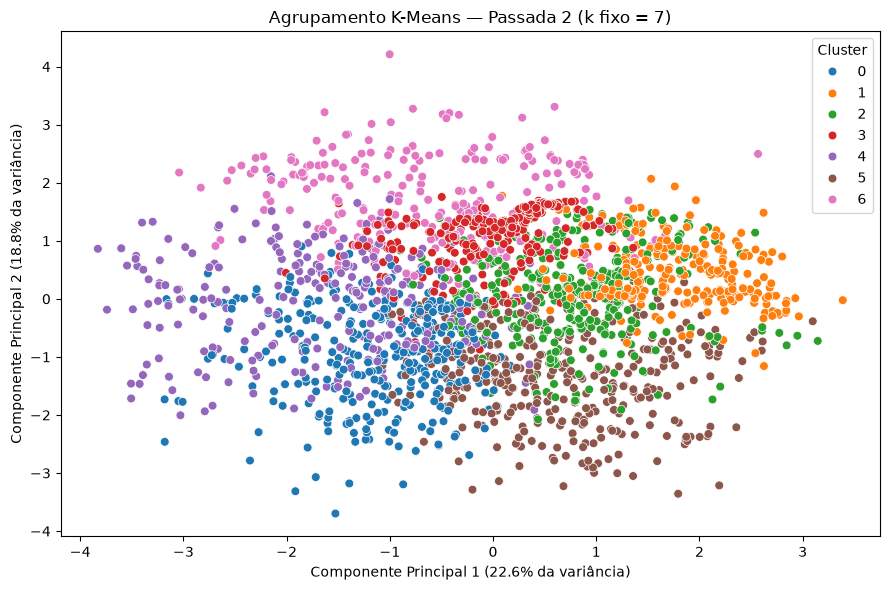

In [5]:
# [IA] Google Gemini – K-Means (Passada 2 com k fixo) e visualização na mesma projeção PCA
k_fixo = y_real.nunique()
print(f"Número real de classes (k fixo): {k_fixo}")

kmeans_fixo = KMeans(n_clusters=k_fixo, random_state=42, n_init=10)
clusters_fixo = kmeans_fixo.fit_predict(X_scaled)

plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters_fixo, palette="tab10", s=40)
plt.title(f"Agrupamento K-Means — Passada 2 (k fixo = {k_fixo})")
plt.xlabel(f"Componente Principal 1 ({var_exp[0]:.1f}% da variância)")
plt.ylabel(f"Componente Principal 2 ({var_exp[1]:.1f}% da variância)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.savefig(out_dir / "clusters_fixo.png", dpi=150)
plt.show()

## 3. Métricas e Matriz de Confusão

Para cada passada:

1. Mapeamos cada cluster para a **classe real majoritária** dentro dele (o K-Means não conhece os rótulos; o mapeamento só é feito aqui, na avaliação).
2. Construímos a **matriz de confusão** entre o rótulo real (linhas) e o rótulo mapeado (colunas). Na Passada 1 a matriz é **retangular**: só existem 4 rótulos previstos possíveis para 7 classes reais. Na Passada 2 ela é **quadrada** (7 × 7); colunas zeradas indicam classes que nenhum cluster representa.
3. Calculamos **acurácia**, **precisão** e **recall** por classe diretamente da matriz:
   - acurácia = soma da diagonal / total;
   - precisão da classe *c* = acertos de *c* / total da coluna *c* (tudo que foi rotulado como *c*);
   - recall da classe *c* = acertos de *c* / total da linha *c* (tudo que realmente é *c*).

As classes são exibidas na ordem ordinal do IMC (de abaixo do peso até obesidade tipo III).

In [6]:
# [IA] Claude Code – funções de mapeamento cluster → classe majoritária, matriz de confusão e métricas por classe
from sklearn.metrics import confusion_matrix

ordem_classes = [
    "Insufficient_Weight", "Normal_Weight", "Overweight_Level_I", "Overweight_Level_II",
    "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III",
]
assert set(ordem_classes) == set(y_real.unique())


def composicao_clusters(clusters, y):
    """Tabela cluster × classe real (contagens), base do mapeamento."""
    tab = pd.crosstab(pd.Series(clusters, name="cluster"), y.rename("classe real"))
    return tab[ordem_classes]


def mapear_clusters(composicao):
    """Associa cada cluster à classe real mais frequente dentro dele."""
    return composicao.idxmax(axis=1).to_dict()


def matriz_confusao(y, y_mapeado, colunas):
    """Linhas = classe real (todas), colunas = rótulos mapeados considerados."""
    mc = confusion_matrix(y, y_mapeado, labels=ordem_classes)
    mc = pd.DataFrame(mc, index=ordem_classes, columns=ordem_classes)
    mc.index.name, mc.columns.name = "real", "mapeado"
    return mc[colunas]


def metricas_da_matriz(mc_quadrada):
    """Acurácia global e precisão/recall por classe a partir de uma matriz 7 × 7."""
    m = mc_quadrada.loc[ordem_classes, ordem_classes].to_numpy()
    acertos = np.diag(m)
    total_coluna = m.sum(axis=0)   # previstos como a classe
    total_linha = m.sum(axis=1)    # realmente da classe
    precisao = np.divide(acertos, total_coluna, out=np.zeros(len(acertos)), where=total_coluna > 0)
    recall = np.divide(acertos, total_linha, out=np.zeros(len(acertos)), where=total_linha > 0)
    por_classe = pd.DataFrame({
        "suporte": total_linha,
        "previstos": total_coluna,
        "acertos": acertos,
        "precisao": precisao,
        "recall": recall,
    }, index=ordem_classes)
    acuracia = acertos.sum() / m.sum()
    return acuracia, por_classe


def plotar_matriz(mc, titulo, arquivo):
    plt.figure(figsize=(1.3 * mc.shape[1] + 4, 6))
    sns.heatmap(mc, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=0.5)
    plt.title(titulo)
    plt.ylabel("Classe real")
    plt.xlabel("Rótulo mapeado (classe majoritária do cluster)")
    plt.tight_layout()
    plt.savefig(out_dir / arquivo, dpi=150)
    plt.show()

### 3.1 Passada 1 — `k` livre (k = 4)

Composição dos clusters (cluster × classe real):


classe real,Insufficient_Weight,Normal_Weight,Overweight_Level_I,Overweight_Level_II,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III
cluster,,,,,,,
0,204,184,125,101,83,2,0
1,10,20,41,55,122,188,141
2,47,50,69,56,73,30,0
3,6,28,41,78,73,77,183


Mapeamento cluster → classe majoritária:


,classe mapeada,tamanho,% da classe majoritária
0,Insufficient_Weight,699,29.2
1,Obesity_Type_II,577,32.6
2,Obesity_Type_I,325,22.5
3,Obesity_Type_III,486,37.7


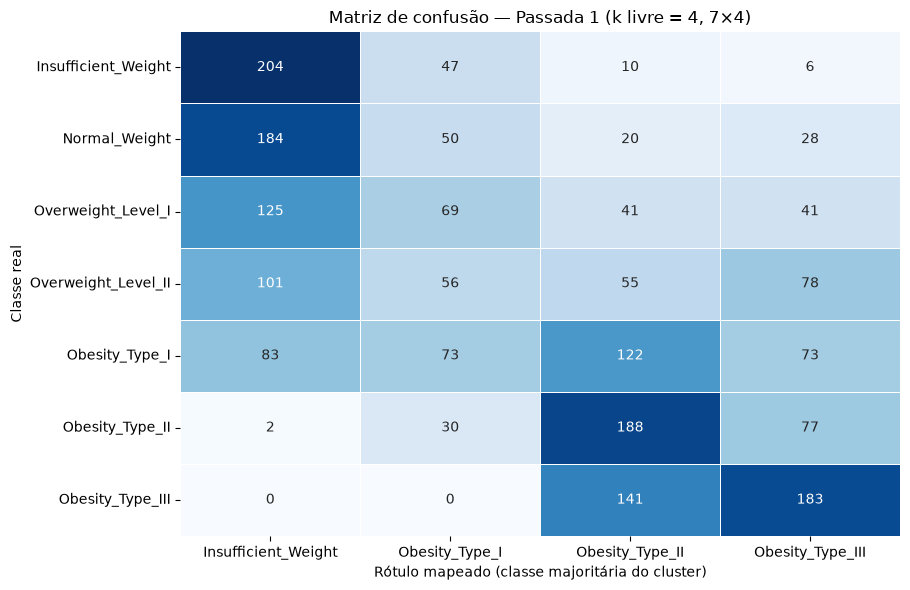

Acurácia (Passada 1): 0.310


,suporte,previstos,acertos,precisao,recall
Insufficient_Weight,267,699,204,0.292,0.764
Normal_Weight,282,0,0,0.000,0.000
Overweight_Level_I,276,0,0,0.000,0.000
Overweight_Level_II,290,0,0,0.000,0.000
Obesity_Type_I,351,325,73,0.225,0.208
Obesity_Type_II,297,577,188,0.326,0.633
Obesity_Type_III,324,486,183,0.377,0.565


In [7]:
# [IA] Claude Code – mapeamento, matriz de confusão retangular e métricas da Passada 1
comp_livre = composicao_clusters(clusters_livre, y_real)
mapa_livre = mapear_clusters(comp_livre)
y_map_livre = pd.Series(clusters_livre).map(mapa_livre)

print("Composição dos clusters (cluster × classe real):")
display(comp_livre)
print("Mapeamento cluster → classe majoritária:")
display(pd.DataFrame({
    "classe mapeada": mapa_livre,
    "tamanho": comp_livre.sum(axis=1),
    "% da classe majoritária": (comp_livre.max(axis=1) / comp_livre.sum(axis=1) * 100).round(1),
}))

# Colunas = apenas os rótulos que algum cluster recebeu → matriz 7 × k (retangular)
colunas_livre = [c for c in ordem_classes if c in set(mapa_livre.values())]
mc_livre = matriz_confusao(y_real, y_map_livre, colunas_livre)
mc_livre.to_csv(out_dir / "matriz_confusao_livre.csv")
plotar_matriz(mc_livre, f"Matriz de confusão — Passada 1 (k livre = {k_livre}, {mc_livre.shape[0]}×{mc_livre.shape[1]})",
              "matriz_confusao_livre.png")

acc_livre, met_livre = metricas_da_matriz(matriz_confusao(y_real, y_map_livre, ordem_classes))
met_livre.to_csv(out_dir / "metricas_livre.csv")
print(f"Acurácia (Passada 1): {acc_livre:.3f}")
display(met_livre.style.format({"precisao": "{:.3f}", "recall": "{:.3f}"}))

### 3.2 Passada 2 — `k` fixo (k = 7)

Composição dos clusters (cluster × classe real):


classe real,Insufficient_Weight,Normal_Weight,Overweight_Level_I,Overweight_Level_II,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III
cluster,,,,,,,
0,85,98,69,55,50,0,0
1,0,0,5,3,25,91,137
2,0,18,38,66,97,119,0
3,7,26,9,19,7,5,187
4,49,47,52,32,55,29,0
5,123,82,60,52,38,0,0
6,3,11,43,63,79,53,0


Mapeamento cluster → classe majoritária:


,classe mapeada,tamanho,% da classe majoritária
0,Normal_Weight,357,27.5
1,Obesity_Type_III,261,52.5
2,Obesity_Type_II,338,35.2
3,Obesity_Type_III,260,71.9
4,Obesity_Type_I,264,20.8
5,Insufficient_Weight,355,34.6
6,Obesity_Type_I,252,31.3


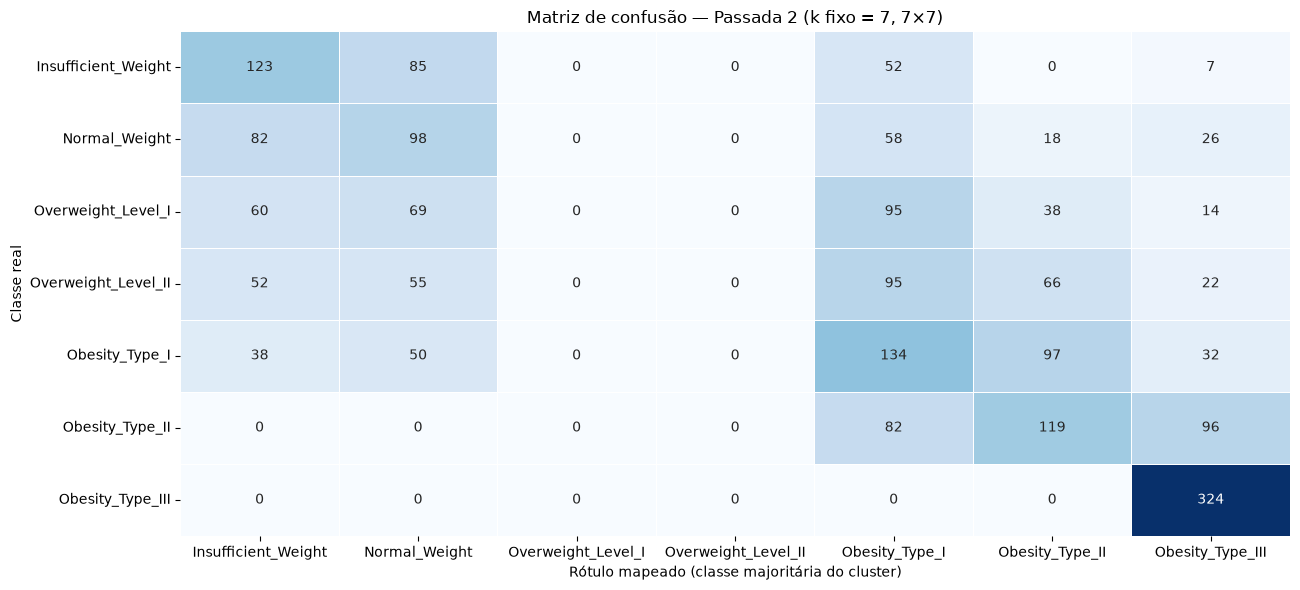

Acurácia (Passada 2): 0.382


,suporte,previstos,acertos,precisao,recall
Insufficient_Weight,267,355,123,0.346,0.461
Normal_Weight,282,357,98,0.275,0.348
Overweight_Level_I,276,0,0,0.000,0.000
Overweight_Level_II,290,0,0,0.000,0.000
Obesity_Type_I,351,516,134,0.260,0.382
Obesity_Type_II,297,338,119,0.352,0.401
Obesity_Type_III,324,521,324,0.622,1.000


Classes que nenhum cluster representa na Passada 2: ['Overweight_Level_I', 'Overweight_Level_II']


In [8]:
# [IA] Claude Code – mapeamento, matriz de confusão quadrada e métricas da Passada 2
comp_fixo = composicao_clusters(clusters_fixo, y_real)
mapa_fixo = mapear_clusters(comp_fixo)
y_map_fixo = pd.Series(clusters_fixo).map(mapa_fixo)

print("Composição dos clusters (cluster × classe real):")
display(comp_fixo)
print("Mapeamento cluster → classe majoritária:")
display(pd.DataFrame({
    "classe mapeada": mapa_fixo,
    "tamanho": comp_fixo.sum(axis=1),
    "% da classe majoritária": (comp_fixo.max(axis=1) / comp_fixo.sum(axis=1) * 100).round(1),
}))

mc_fixo = matriz_confusao(y_real, y_map_fixo, ordem_classes)   # 7 × 7
mc_fixo.to_csv(out_dir / "matriz_confusao_fixo.csv")
plotar_matriz(mc_fixo, f"Matriz de confusão — Passada 2 (k fixo = {k_fixo}, 7×7)", "matriz_confusao_fixo.png")

acc_fixo, met_fixo = metricas_da_matriz(mc_fixo)
met_fixo.to_csv(out_dir / "metricas_fixo.csv")
print(f"Acurácia (Passada 2): {acc_fixo:.3f}")
display(met_fixo.style.format({"precisao": "{:.3f}", "recall": "{:.3f}"}))

classes_sem_cluster = [c for c in ordem_classes if c not in set(mapa_fixo.values())]
print("Classes que nenhum cluster representa na Passada 2:", classes_sem_cluster)

### 3.3 Perfil dos clusters (Passada 2) e IMC por classe

Tabelas de apoio a discussao, com as medias das variaveis na escala original e a proporcao de mulheres em cada cluster da Passada 2, e a faixa de IMC (peso dividido pela altura ao quadrado) em cada classe real.

In [ ]:
# [IA] Claude Code - perfil dos clusters da Passada 2 na escala original e IMC por classe real
perfil_fixo = (
    df.assign(cluster=clusters_fixo)
    .groupby("cluster")
    .agg(
        peso_medio=("Weight", "mean"),
        altura_media=("Height", "mean"),
        idade_media=("Age", "mean"),
        NCP_medio=("NCP", "mean"),
        FAF_medio=("FAF", "mean"),
        FCVC_medio=("FCVC", "mean"),
        pct_mulheres=("Gender", lambda s: (s == "Female").mean() * 100),
        tamanho=("Gender", "size"),
    )
)
perfil_fixo.insert(0, "classe mapeada", pd.Series(mapa_fixo))
perfil_fixo.to_csv(out_dir / "perfil_clusters_fixo.csv")
print("Perfil dos clusters da Passada 2 (medias na escala original)")
display(perfil_fixo.round(2))

imc = df["Weight"] / df["Height"] ** 2
imc_por_classe = imc.groupby(y_real).agg(["min", "median", "max"]).loc[ordem_classes]
imc_por_classe.columns = ["IMC minimo", "IMC mediano", "IMC maximo"]
imc_por_classe.to_csv(out_dir / "imc_por_classe.csv")
print("IMC (peso dividido pela altura ao quadrado) por classe real")
display(imc_por_classe.round(1))

Perfil dos clusters da Passada 2 (medias na escala original)


,classe mapeada,peso_medio,altura_media,idade_media,NCP_medio,FAF_medio,FCVC_medio,pct_mulheres,tamanho
cluster,,,,,,,,,
0,Normal_Weight,65.36,1.65,20.66,3.06,0.74,2.03,60.22,357
1,Obesity_Type_III,127.33,1.78,23.77,2.90,1.35,2.91,52.11,261
2,Obesity_Type_II,102.33,1.79,24.69,2.78,0.84,1.94,2.66,338
3,Obesity_Type_III,98.60,1.65,24.78,3.03,0.21,2.97,90.00,260
4,Obesity_Type_I,70.42,1.62,21.64,1.18,0.67,2.40,67.05,264
5,Insufficient_Weight,69.00,1.74,20.61,3.15,2.10,2.55,34.93,355
6,Obesity_Type_I,84.91,1.66,37.41,2.50,0.93,2.40,55.56,252


IMC (peso dividido pela altura ao quadrado) por classe real


,IMC minimo,IMC mediano,IMC maximo
NObeyesdad,,,
Insufficient_Weight,13.0,17.5,19.1
Normal_Weight,18.5,22.1,24.9
Overweight_Level_I,22.8,26.0,28.8
Overweight_Level_II,25.7,28.2,30.4
Obesity_Type_I,29.9,32.2,35.2
Obesity_Type_II,34.0,36.4,39.8
Obesity_Type_III,36.8,41.9,50.8


## 4. Discussão Crítica

### 4.1 Comparação quantitativa entre as passadas

Tabela de apoio para a discussão: métricas globais, métricas médias (macro) e quantas classes reais cada passada consegue representar. Como referência, incluímos a acurácia de um classificador trivial que sempre prevê a classe mais frequente.

Acurácia do baseline (sempre a classe mais frequente): 0.168


,k,acurácia,precisão macro,recall macro,classes representadas,clusters com mesmo rótulo
passada,,,,,,
1 — k livre,4,0.310,0.174,0.310,4/7,0
2 — k fixo,7,0.382,0.265,0.370,5/7,2


,recall P1 (k livre),recall P2 (k fixo),precisão P1,precisão P2
Insufficient_Weight,0.764,0.461,0.292,0.346
Normal_Weight,0.000,0.348,0.000,0.275
Overweight_Level_I,0.000,0.000,0.000,0.000
Overweight_Level_II,0.000,0.000,0.000,0.000
Obesity_Type_I,0.208,0.382,0.225,0.260
Obesity_Type_II,0.633,0.401,0.326,0.352
Obesity_Type_III,0.565,1.000,0.377,0.622


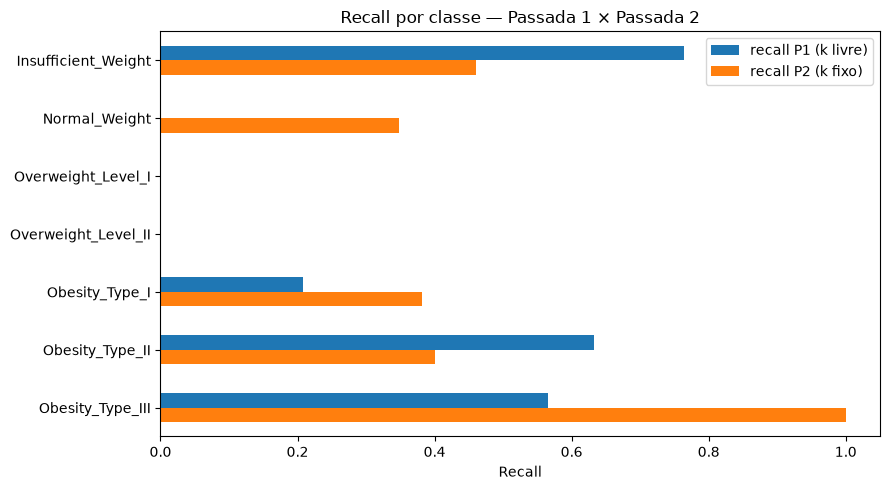

In [9]:
# [IA] Claude Code – tabela comparativa das duas passadas e recall por classe lado a lado
baseline = y_real.value_counts(normalize=True).max()

def resumo(nome, k, acc, met, mapa):
    representadas = len(set(mapa.values()))
    return {
        "passada": nome,
        "k": k,
        "acurácia": acc,
        "precisão macro": met["precisao"].mean(),
        "recall macro": met["recall"].mean(),
        "classes representadas": f"{representadas}/{len(ordem_classes)}",
        "clusters com mesmo rótulo": k - representadas,
    }

comparacao = pd.DataFrame([
    resumo("1 — k livre", k_livre, acc_livre, met_livre, mapa_livre),
    resumo("2 — k fixo", k_fixo, acc_fixo, met_fixo, mapa_fixo),
]).set_index("passada")
comparacao.to_csv(out_dir / "comparacao_passadas.csv")
print(f"Acurácia do baseline (sempre a classe mais frequente): {baseline:.3f}")
display(comparacao.style.format({"acurácia": "{:.3f}", "precisão macro": "{:.3f}", "recall macro": "{:.3f}"}))

recall_lado_a_lado = pd.DataFrame({
    "recall P1 (k livre)": met_livre["recall"],
    "recall P2 (k fixo)": met_fixo["recall"],
    "precisão P1": met_livre["precisao"],
    "precisão P2": met_fixo["precisao"],
})
display(recall_lado_a_lado.round(3))

ax = recall_lado_a_lado[["recall P1 (k livre)", "recall P2 (k fixo)"]].plot.barh(figsize=(9, 5))
ax.set_xlabel("Recall")
ax.set_title("Recall por classe — Passada 1 × Passada 2")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(out_dir / "recall_comparacao.png", dpi=150)
plt.show()

### 4.2 Discussão

**Qual passada gerou grupos mais coerentes?**

Pelas métricas, a Passada 2 (k = 7) foi melhor. A acurácia subiu de 0,310 para 0,382, a precisão média de 0,174 para 0,265 e o recall médio de 0,310 para 0,370. Ela também representa 5 das 7 classes, contra 4 na Passada 1. As duas passadas superam o baseline de 0,168 (prever sempre a classe mais frequente), então os clusters carregam alguma informação sobre o nível de obesidade, mas pouca: na melhor das passadas, quase 2 em cada 3 pessoas caem num cluster cuja classe majoritária não é a sua.

A Passada 1 só não fica tão atrás porque, com menos clusters, cada um "cobre" mais classes vizinhas. A pureza dos clusters mostra isso: na Passada 1 a classe majoritária ocupa entre 22,5% e 37,7% de cada cluster, ou seja, nenhum grupo é dominado por uma classe. Na Passada 2 aparecem grupos mais puros, com destaque para o cluster 3 (71,9% `Obesity_Type_III`) e o cluster 1 (52,5% `Obesity_Type_III`). Por isso consideramos a Passada 2 a mais coerente em relação às classes reais, ainda que coerente aqui signifique "menos misturada", não "bem separada".

O ganho da Passada 2, porém, não é uniforme. `Obesity_Type_III` passa a ter recall 1,0, mas `Insufficient_Weight` cai de 0,764 para 0,461 e `Obesity_Type_II` de 0,633 para 0,401, porque essas classes foram divididas entre mais clusters.

**Por que algumas classes nunca são previstas?**

Na Passada 2, dois pares de clusters receberam o mesmo rótulo (dois viraram `Obesity_Type_III` e dois `Obesity_Type_I`). Sobram só 5 rótulos distintos, e `Overweight_Level_I` e `Overweight_Level_II` nunca são previstas (recall 0 nas duas passadas). Essas pessoas estão espalhadas: `Overweight_Level_II` aparece com 55, 66 e 63 registros nos clusters 0, 2 e 6, e em nenhum deles é maioria. Isso faz sentido porque as faixas de sobrepeso ficam no meio da escala de IMC (cerca de 23 a 30) e se sobrepõem às classes vizinhas em todas as variáveis.

**O que o K-Means realmente agrupou**

Olhando os centroides, os clusters seguem eixos que não são o nível de obesidade:

- *Sexo/altura:* na Passada 2, os clusters 2 e 3 têm peso médio parecido (102 kg e 99 kg), mas o cluster 2 tem altura média de 1,79 m e 3% de mulheres, e o cluster 3 tem 1,65 m e 90% de mulheres. Como o mesmo peso numa pessoa mais baixa gera IMC maior, o cluster masculino fica com maioria `Obesity_Type_II` e o feminino com `Obesity_Type_III`. A separação veio da altura, não do grau de obesidade.
- *Hábitos:* o cluster 4 se diferencia por ter em média 1,2 refeições principais por dia (`NCP`), o cluster 5 pela atividade física alta (`FAF` = 2,1) e o cluster 6 pela idade (37 anos contra cerca de 21–25 nos demais). Nenhum desses eixos coincide com uma faixa de IMC, e por isso esses clusters misturam várias classes.

Ou seja, o K-Means encontrou perfis de estilo de vida e de corpo, que é o que as 8 variáveis descrevem com peso igual, enquanto as classes reais dependem apenas de duas delas (peso e altura, via IMC).

**Granularidade das classes**

As 7 classes são cortes de uma única variável contínua (IMC). As faixas vizinhas são estreitas e sem fronteira natural nos dados: sobrepeso I vai de 22,8 a 28,8 e sobrepeso II de 25,7 a 30,4, por exemplo. Um método não supervisionado não tem como saber onde ficam esses cortes, e as outras 6 variáveis, padronizadas com o mesmo peso, diluem a informação de peso e altura. Os dados parecem sustentar uma divisão mais grosseira (abaixo do peso/normal, sobrepeso, obesidade, obesidade severa) do que as 7 classes, o que também está de acordo com o cotovelo sem dobra nítida.

**Limitações**

- Usamos só as variáveis numéricas; as categóricas (histórico familiar, `FAVC`, transporte, sexo) ficaram de fora e podem ter informação útil.
- Cerca de 77% do dataset foi gerado sinteticamente (SMOTE) pelos autores. Isso explica valores fracionários em variáveis que deveriam ser discretas (`FCVC`, `NCP`, `FAF`, `TUE`, `CH2O`) e pode criar padrões artificiais.
- A escolha de k = 4 foi feita pelo cotovelo, que não tem um ponto de inflexão claro.
- O mapeamento pela classe majoritária permite que vários clusters recebam o mesmo rótulo e deixa classes sem representação, o que penaliza as métricas por classe.
- O K-Means assume grupos esféricos e de tamanho parecido, o que não precisa valer para estes dados.